# Clustering quantistico di testi: 500 articoli arXiv di ottobre 2026

**Dati**: `load_arxiv_recent()` — 500 articoli reali (titolo + abstract) pubblicati su arXiv tra l'11 e il 29
ottobre 2026, 100 per ciascuna di 5 aree: fisica quantistica, finanza quantitativa, linguistica computazionale,
astrofisica, biologia quantitativa.

**Obiettivo**: ritrovare le 5 aree **senza usare le etichette** (clustering non supervisionato), con la libreria
`scikit-qml` (tutto scritto da zero in NumPy). Le etichette vere servono solo alla fine per valutare.

**Pipeline**
```
testo ──► TF-IDF / Word2Vec ──► vettore documento ──► PCA a 8 dim ──► 8 qubit (angle encoding)
       ──► kernel quantistico k(x,y)=|<φ(x)|φ(y)>|² ──► clustering (QKMeans / spettrale) ──► etichette automatiche
```

Installazione (una volta): `pip install -e scikit-qml` (cartella estratta da `scikit-qml.zip`).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skqml.text import tokenize, STOP_WORDS, cluster_labels, cluster_keywords
from skqml.embeddings import embed_documents
from skqml.models import (QKMeans, QSpectralClustering, QuantumKernel, adjusted_rand_score,
                          normalized_mutual_info_score, silhouette_score)
from skqml.tuning import ClusterSearch

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
colori = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]

## 1. I dati

In [2]:
from skqml.datasets import load_arxiv_recent
arxiv = load_arxiv_recent()          # dati inclusi nella libreria
df = pd.DataFrame(arxiv.meta)
nomi_aree = {"quant-ph": "Fisica quantistica", "q-fin": "Finanza quantitativa", "cs.CL": "Linguistica computazionale",
             "astro-ph": "Astrofisica", "q-bio": "Biologia quantitativa"}
df["area"] = [nomi_aree[arxiv.target_names[i]] for i in arxiv.y]
print(df.shape)
df[["id", "date", "area", "title"]].head(8)

(500, 6)


,id,date,area,title
0,2610.40652v1,2026-10-29,Fisica quantistica,Reconstructing hidden observables via quantum ...
1,2610.40642v1,2026-10-29,Fisica quantistica,Comparison of entangling strategies for unitar...
2,2610.40638v1,2026-10-29,Fisica quantistica,Entanglement diagnostics of stochastic-resetti...
3,2610.40628v1,2026-10-29,Fisica quantistica,Locality in Dissipative Ground-State Preparation
4,2610.40624v1,2026-10-29,Fisica quantistica,Left-Handed Transmission Lines for the Dynamic...
5,2610.40623v1,2026-10-29,Fisica quantistica,Optimal Diamond Distance Estimation for Unitar...
6,2610.40612v1,2026-10-29,Fisica quantistica,Exceptional Points as Witnesses of Non-Gaussia...
7,2610.40595v1,2026-10-29,Fisica quantistica,Optimal detuning and gate time for strongly dr...


/tmp/ipykernel_190/586496177.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot([df.loc[df.area == a, "n_parole"] for a in aree], vert=False, tick_labels=aree)


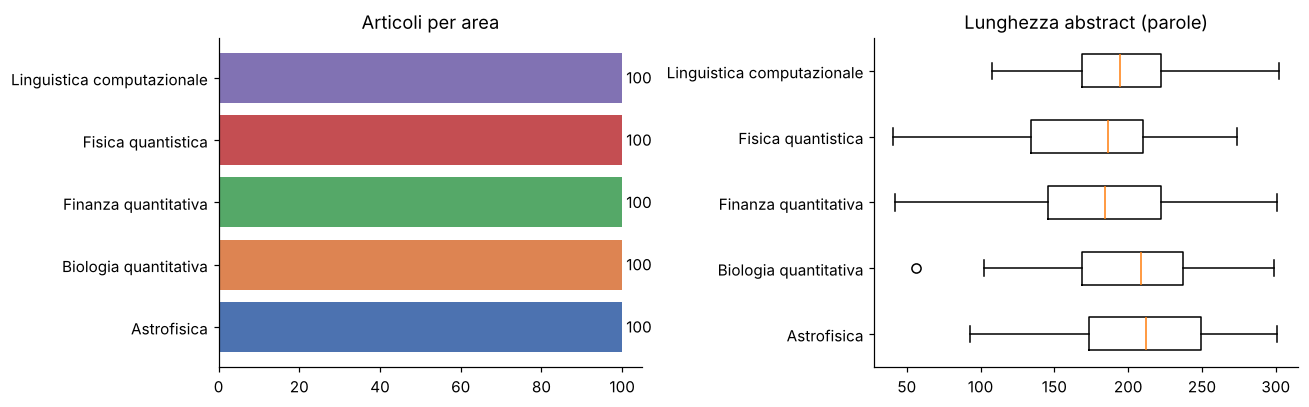

Periodo: 2026-10-11 → 2026-10-29


In [3]:
aree = sorted(df["area"].unique())
df["testo"] = df["title"] + ". " + df["abstract"]
df["n_parole"] = df["abstract"].str.split().str.len()
y = df["area"].map({a: i for i, a in enumerate(aree)}).values
testi = df["testo"].tolist()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
conteggi = df["area"].value_counts().reindex(aree)
ax[0].barh(aree, conteggi.values, color=colori)
for i, v in enumerate(conteggi.values):
    ax[0].text(v + 1, i, str(v), va="center")
ax[0].set_title("Articoli per area")
ax[1].boxplot([df.loc[df.area == a, "n_parole"] for a in aree], vert=False, tick_labels=aree)
ax[1].set_title("Lunghezza abstract (parole)")
plt.tight_layout(); plt.show()
print("Periodo:", df["date"].min(), "→", df["date"].max())

## 2. Le parole tipiche di ogni area
Prima di fare clustering guardiamo quali parole (dopo aver tolto le *stop words*) dominano ciascuna area:
se le aree hanno vocabolari diversi, il clustering ha buone chance di separarle.

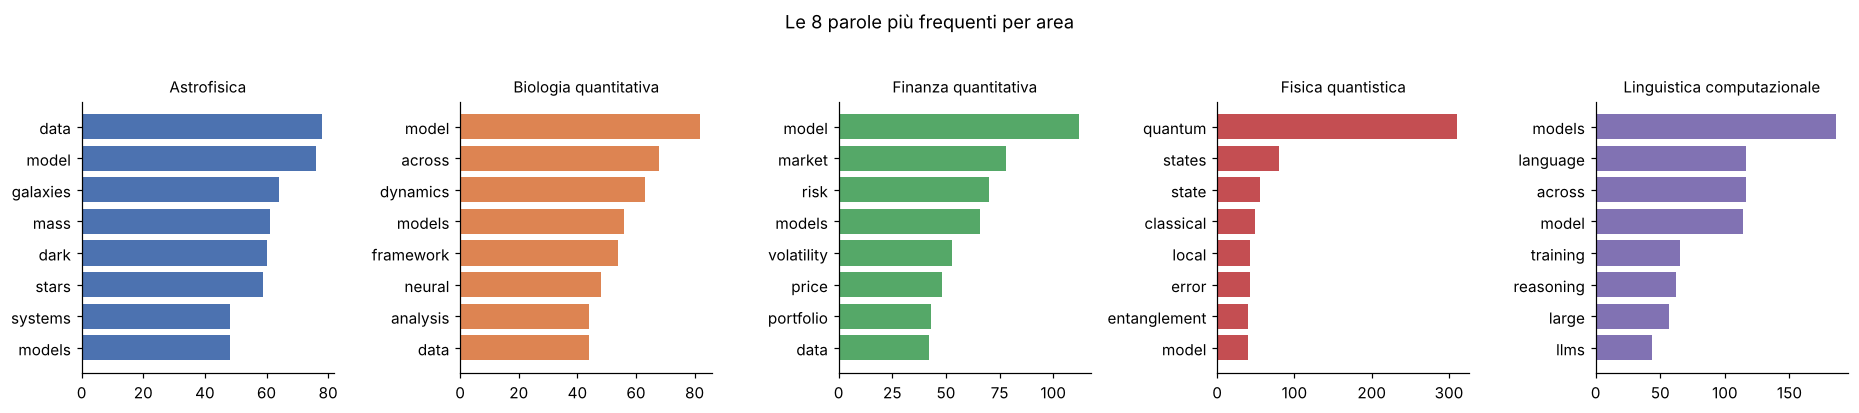

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for k, a in enumerate(aree):
    parole = pd.Series([w for t in df.loc[df.area == a, "testo"] for w in tokenize(t, STOP_WORDS)])
    top = parole.value_counts().head(8)[::-1]
    axes[k].barh(top.index, top.values, color=colori[k])
    axes[k].set_title(a, fontsize=10)
plt.suptitle("Le 8 parole più frequenti per area", y=1.03)
plt.tight_layout(); plt.show()

## 3. Dal testo ai vettori: tre rappresentazioni

| metodo | idea | cosa cattura |
|---|---|---|
| `tfidf_lsa` | TF-IDF → SVD troncata (LSA) | argomenti (parole che compaiono insieme nei documenti) |
| `word2vec` | Word2Vec skip-gram addestrato su questi 500 testi, media pesata TF-IDF | significato distribuzionale delle parole |
| `hybrid` | [LSA ‖ Word2Vec] | entrambe le cose |

Ogni rappresentazione viene ridotta con PCA a **8 componenti = 8 qubit**. `max_df=0.5` scarta le parole presenti in
più della metà dei documenti (es. *we, show, model*), che non distinguono le aree.

In [5]:
rappresentazioni = {}
for metodo in ["tfidf_lsa", "word2vec", "hybrid"]:
    t0 = time.time()
    rappresentazioni[metodo] = embed_documents(testi, metodo, n_components=8, max_df=0.5)
    print(f"{metodo:10s} → {rappresentazioni[metodo].shape}  ({time.time() - t0:.1f}s)")

tfidf_lsa  → (500, 8)  (0.9s)


word2vec   → (500, 8)  (73.2s)


hybrid     → (500, 8)  (68.4s)


## 4. Il kernel quantistico
Ogni documento $x\in\mathbb{R}^8$ diventa uno stato a 8 qubit $|\phi(x)\rangle=\bigotimes_j R_Y(x_j)|0\rangle$
(angle encoding). La similarità tra due documenti è la **fedeltà** $k(x,y)=|\langle\phi(x)|\phi(y)\rangle|^2\in[0,1]$.
Se i documenti sono ordinati per area, la matrice kernel deve mostrare **blocchi chiari sulla diagonale**.

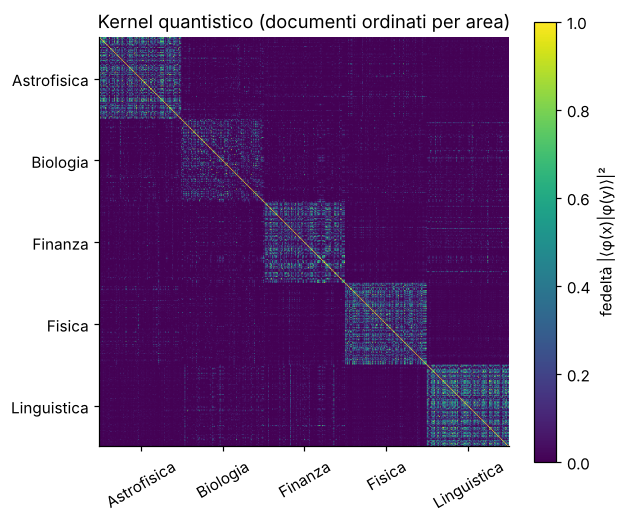

Fedeltà media dentro la stessa area: 0.177 | tra aree diverse: 0.013


In [6]:
kernel = QuantumKernel("angle", reps=1)
x_h = rappresentazioni["hybrid"]
ordine = np.argsort(y, kind="stable")
xs = (x_h - x_h.mean(0)) / x_h.std(0)           # stessa standardizzazione usata dai modelli
k = kernel(xs[ordine])

fig, ax = plt.subplots(figsize=(6, 5.2))
im = ax.imshow(k, cmap="viridis")
tacche = [100 * i + 50 for i in range(5)]
ax.set_xticks(tacche); ax.set_xticklabels([a.split()[0] for a in aree], rotation=30)
ax.set_yticks(tacche); ax.set_yticklabels([a.split()[0] for a in aree])
plt.colorbar(im, label="fedeltà |⟨φ(x)|φ(y)⟩|²")
ax.set_title("Kernel quantistico (documenti ordinati per area)")
plt.show()
medie = np.array([[k[100*i:100*i+100, 100*j:100*j+100].mean() for j in range(5)] for i in range(5)])
print("Fedeltà media dentro la stessa area:", medie.diagonal().mean().round(3),
      "| tra aree diverse:", medie[~np.eye(5, dtype=bool)].mean().round(3))

## 5. Confronto: rappresentazione × algoritmo
- **QKMeans**: k-means nello spazio di Hilbert (distanze $d^2=k(x,x)+k(y,y)-2k(x,y)$).
- **Spettrale quantistico**: grafo dei 10 vicini più prossimi secondo il kernel, poi autovettori del Laplaciano
  (Ng–Jordan–Weiss). Gestisce cluster non sferici.

Metriche (calcolate *dopo*, con le etichette vere): **ARI** (0 = caso, 1 = perfetto) e **NMI**.

In [7]:
righe = []
for metodo, x in rappresentazioni.items():
    for nome, modello in [("QKMeans", QKMeans(5, QuantumKernel("angle", 1))),
                          ("Spettrale quantistico", QSpectralClustering(5, QuantumKernel("angle", 1), affinity="knn"))]:
        t0 = time.time()
        pred = modello.fit(x).labels_
        righe.append({"rappresentazione": metodo, "algoritmo": nome,
                      "ARI": adjusted_rand_score(y, pred), "NMI": normalized_mutual_info_score(y, pred),
                      "tempo (s)": time.time() - t0})
risultati = pd.DataFrame(righe)
risultati.round(3)

,rappresentazione,algoritmo,ARI,NMI,tempo (s)
0,tfidf_lsa,QKMeans,0.668,0.705,0.125
1,tfidf_lsa,Spettrale quantistico,0.817,0.800,0.078
2,word2vec,QKMeans,0.397,0.514,0.086
3,word2vec,Spettrale quantistico,0.480,0.514,0.085
4,hybrid,QKMeans,0.509,0.672,0.075
5,hybrid,Spettrale quantistico,0.865,0.842,0.067


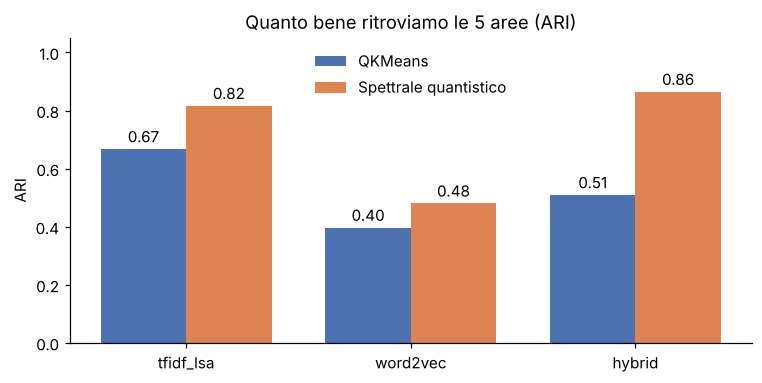

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
pivot = risultati.pivot(index="rappresentazione", columns="algoritmo", values="ARI").loc[["tfidf_lsa", "word2vec", "hybrid"]]
larg = 0.38
for j, col in enumerate(pivot.columns):
    barre = ax.bar(np.arange(3) + (j - 0.5) * larg, pivot[col], larg, label=col, color=colori[j])
    ax.bar_label(barre, fmt="%.2f", padding=2)
ax.set_xticks(range(3)); ax.set_xticklabels(pivot.index)
ax.set_ylabel("ARI"); ax.set_ylim(0, 1.05); ax.legend(frameon=False)
ax.set_title("Quanto bene ritroviamo le 5 aree (ARI)")
plt.show()

## 6. Quanti cluster? Sceglierlo senza etichette
Nella realtà il numero di aree non è noto. `ClusterSearch` prova $k=2,\dots,8$ e sceglie quello con la
**silhouette** migliore (coesione interna vs separazione), senza mai guardare le etichette.

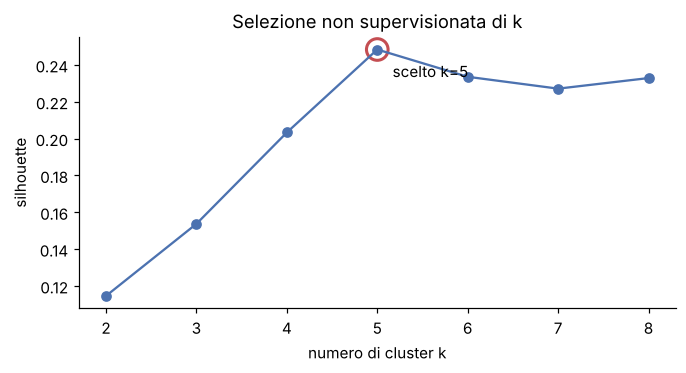

In [9]:
ricerca = ClusterSearch(QSpectralClustering(kernel=QuantumKernel("angle", 1), affinity="knn"),
                        {"n_clusters": list(range(2, 9))}, scoring="silhouette").fit(x_h)
tab = pd.DataFrame([{"k": r["params"]["n_clusters"], "silhouette": r["mean_score"]} for r in ricerca.cv_results_]).sort_values("k")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(tab.k, tab.silhouette, "o-", color=colori[0])
k_best = ricerca.best_params_["n_clusters"]
ax.scatter([k_best], [ricerca.best_score_], s=200, facecolors="none", edgecolors=colori[3], lw=2)
ax.annotate(f"scelto k={k_best}", (k_best, ricerca.best_score_), xytext=(10, -18), textcoords="offset points")
ax.set_xlabel("numero di cluster k"); ax.set_ylabel("silhouette")
ax.set_title("Selezione non supervisionata di k")
plt.show()

## 7. Il modello finale: hybrid + spettrale quantistico, k = 5
I cluster ricevono un **nome automatico** con c-TF-IDF: le parole (anche bigrammi) più specifiche di ciascun cluster
rispetto agli altri.

In [10]:
finale = QSpectralClustering(5, QuantumKernel("angle", 1), affinity="knn").fit(x_h)
pred = finale.labels_
nomi = cluster_labels(testi, pred)
parole_chiave = cluster_keywords(testi, pred, top_n=6)

riassunto = []
for c in range(5):
    m = pred == c
    area_prev = pd.Series(df.loc[m, "area"]).value_counts()
    riassunto.append({"cluster": c, "nome automatico": nomi[c], "n": int(m.sum()),
                      "area prevalente": area_prev.index[0], "purezza": area_prev.iloc[0] / m.sum(),
                      "parole chiave": ", ".join(parole_chiave[c])})
riassunto = pd.DataFrame(riassunto)
print(f"ARI = {adjusted_rand_score(y, pred):.3f}   NMI = {normalized_mutual_info_score(y, pred):.3f}")
riassunto.style.format({"purezza": "{:.0%}"}).hide(axis="index")

ARI = 0.865   NMI = 0.842


cluster,nome automatico,n,area prevalente,purezza,parole chiave
0,de novo,103,Biologia quantitativa,89%,"model, dynamics, across, neural, framework, analysis"
1,limit order,95,Finanza quantitativa,98%,"market, risk, model, volatility, price, portfolio"
2,quantum states,102,Fisica quantistica,95%,"quantum, states, classical, state, entanglement, error"
3,dark matter,100,Astrofisica,94%,"galaxies, dark, stars, mass, data, stellar"
4,language models,100,Linguistica computazionale,96%,"models, language, across, model, reasoning, training"


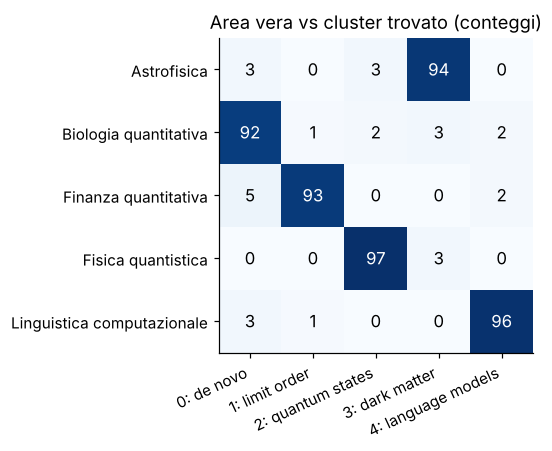

In [11]:
conf = pd.crosstab(pd.Series(df["area"], name="area vera"),
                   pd.Series([f"{c}: {nomi[c]}" for c in pred], name="cluster trovato"))
fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(conf.values, cmap="Blues")
for i in range(conf.shape[0]):
    for j in range(conf.shape[1]):
        v = conf.values[i, j]
        ax.text(j, i, v, ha="center", va="center", color="white" if v > 50 else "black", fontsize=11)
ax.set_xticks(range(conf.shape[1])); ax.set_xticklabels(conf.columns, rotation=25, ha="right")
ax.set_yticks(range(conf.shape[0])); ax.set_yticklabels(conf.index)
ax.set_title("Area vera vs cluster trovato (conteggi)")
plt.tight_layout(); plt.show()

## 8. Mappa 2-D dei documenti
Proiezione PCA delle 8 componenti: a sinistra i colori sono i **cluster trovati**, a destra le **aree vere**.
Le croci nere segnano i documenti assegnati a un cluster la cui area prevalente è diversa dalla loro.

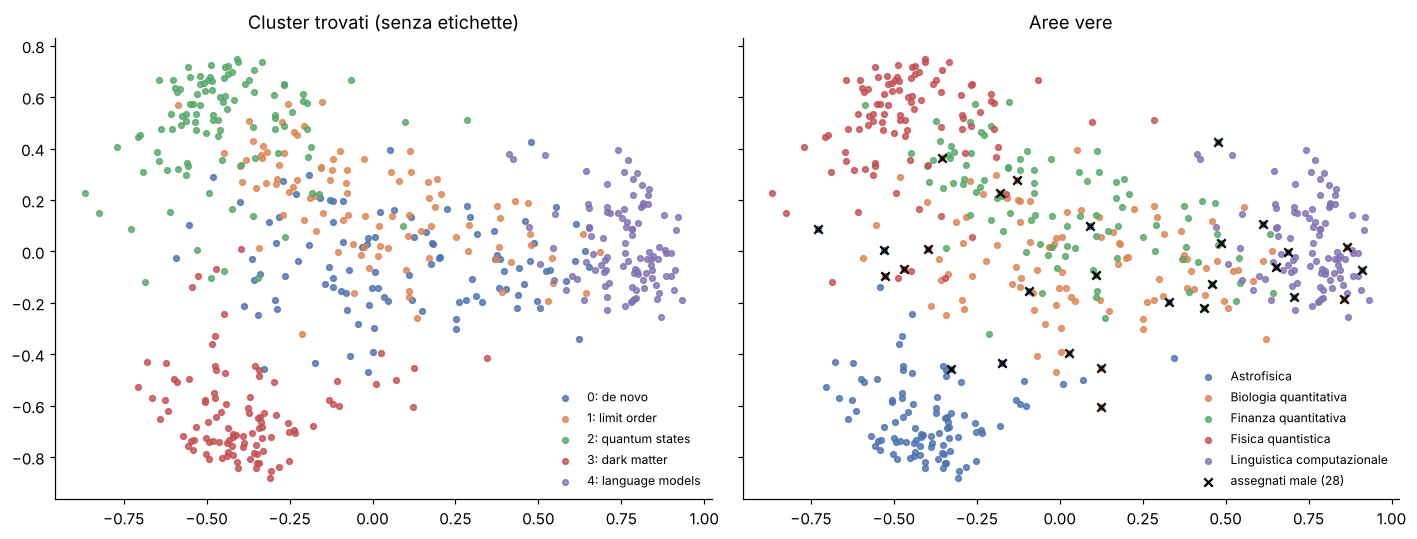

In [12]:
xc = x_h - x_h.mean(0)
p2 = xc @ np.linalg.svd(xc, full_matrices=False)[2][:2].T
area_del_cluster = riassunto.set_index("cluster")["area prevalente"]
errati = df["area"].values != area_del_cluster.loc[pred].values

fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for c in range(5):
    ax[0].scatter(*p2[pred == c].T, s=14, color=colori[c], label=f"{c}: {nomi[c]}", alpha=.8)
for i, a in enumerate(aree):
    ax[1].scatter(*p2[y == i].T, s=14, color=colori[i], label=a, alpha=.8)
ax[1].scatter(*p2[errati].T, marker="x", color="black", s=30, label=f"assegnati male ({errati.sum()})")
ax[0].set_title("Cluster trovati (senza etichette)"); ax[1].set_title("Aree vere")
for a_ in ax:
    a_.legend(fontsize=8, frameon=False, loc="best")
plt.tight_layout(); plt.show()

## 9. Gli errori hanno senso?
Alcuni articoli stanno a cavallo tra due aree (es. *quantum* in astrofisica, *language models* applicati alla
biologia). Ecco i titoli assegnati a un cluster diverso dalla loro area:

In [13]:
pd.set_option("display.max_colwidth", 110)
err = df.loc[errati, ["area", "title"]].copy()
err["finito nel cluster"] = [f"{c}: {nomi[c]}" for c in pred[errati]]
err.head(12)

,area,title,finito nel cluster
4,Fisica quantistica,Left-Handed Transmission Lines for the Dynamical Casimir Effect,3: dark matter
60,Fisica quantistica,Signatures of Narrowband and Ultrashort-Pulse-Like Probing in Coherent Anti-Stokes Raman Scattering Using ...,3: dark matter
71,Fisica quantistica,Drive-tunable Floquet exchange spectroscopy with Hong--Ou--Mandel interference,3: dark matter
120,Finanza quantitativa,Det-MASO: Diversity-Regularized Multi-Agent Sequential Optimization for Factor Generation,0: de novo
125,Finanza quantitativa,What FLARE's Published Numbers Actually Measure,0: de novo
133,Finanza quantitativa,Uncertainty Quantification for Financial Foundation Models: A Survey,4: language models
150,Finanza quantitativa,Regime-Aware Interpretable Ranking for Sector Rotation,0: de novo
184,Finanza quantitativa,The Missile and the Toll: Two-Way Flow Through the Strait of Hormuz,0: de novo
186,Finanza quantitativa,How Well Do LLMs Perform in Peer Review? Evidence from Finance and Accounting,4: language models
193,Finanza quantitativa,4Cast Lab: Open-Source App for Machine Learning & Statistical Analysis,0: de novo


## 10. Conclusioni
- Su 500 articoli reali di ottobre 2026, il clustering quantistico ritrova le 5 aree senza etichette;
  la combinazione migliore è **rappresentazione ibrida (LSA + Word2Vec) + spettrale quantistico** (tabella sez. 5).
- Word2Vec da solo è il più debole: 500 testi sono pochi per imparare buoni vettori di parola; LSA porta
  l'informazione "di argomento" che manca.
- Il kernel quantistico a 8 qubit (angle encoding) è un kernel di fedeltà calcolato esattamente in simulazione:
  su dati così il vantaggio rispetto a un kernel classico non è garantito — il punto qui è la pipeline completa.
- I nomi automatici dei cluster (c-TF-IDF) corrispondono bene alle aree, e gli errori sono quasi tutti articoli
  interdisciplinari.